# Topic Modelling of Soft-Included Abstracts

Exploratory content analysis of the papers that passed the **soft inclusion criterion**
during screening — i.e. papers included by **at least one** annotator (`n_include >= 1`).
The merged screening verdicts were produced in
[03_iaa_analysis.ipynb](03_iaa_analysis.ipynb) and saved to
`../data/processed/iaa/annotated/iaa_merged.xlsx`.

We run two complementary topic-modelling methods over the abstracts and compare them:

- **BERTopic** — embedding + clustering (UMAP → HDBSCAN → c-TF-IDF).
- **LDA** (gensim) — probabilistic bag-of-words topics.

> **⚠️ Small-corpus caveat.** There are only **30** soft-included papers. Topic models are
> unstable on so few documents, so the results below are **exploratory / didactic**, not
> definitive themes. All 30 papers have non-null abstracts (mean ~1650 chars), so no
> imputation is needed. Models are deliberately tuned for a small corpus rather than run at
> library defaults.

In [1]:
import sys
sys.path.append("../")  # go up one level from notebooks/ to project root

from pathlib import Path

import numpy as np
import pandas as pd

RANDOM_STATE = 42
iaa_dir = Path("../data/processed/iaa/annotated")

## 1. Load the soft-included corpus

Filter the merged table to `n_include >= 1` (30 papers) and build the modelling text from
**title + abstract** — the title adds a bit of signal on such a tiny corpus.

In [2]:
merged = pd.read_excel(iaa_dir / "iaa_merged.xlsx")

corpus = merged[merged["n_include"] >= 1].copy().reset_index(drop=True)
assert corpus["abstract"].notna().all(), "some soft-included papers have no abstract"

# Modelling text = title + abstract.
corpus["text"] = (corpus["title"].fillna("") + ". " + corpus["abstract"].fillna("")).str.strip()

keep = ["paper_id", "title", "year", "n_include",
        "MC_Research area", "ME_Research area", "TC_Research area", "text"]
corpus = corpus[keep]
print(f"Soft-included papers: {len(corpus)}")
corpus[["paper_id", "title", "year", "n_include"]].head(10)

Soft-included papers: 30


,paper_id,title,year,n_include
0,06e5f45d08bfd760,Social media discourse as a window into energy...,2025,1
1,1aecf98d861b4aea,Navigating the Map of Environmental-policy Nar...,2025,1
2,295dd9e3895f13f1,Opinion-based homogeneity on youtube: Combinin...,2020,2
3,2d9dff826cc1e5bd,Climate Change Myths Detection Using Dynamical...,2022,2
4,3b8b0f6e81d0f3f5,ClimateCheck2025: Multi-Stage Retrieval Meets ...,2025,2
5,4778b166d9eb776c,LLM-Supported Content Analysis of Motivated Re...,2025,3
6,4b2e90eb151bcba8,Good and Bad Science? Spanish-Speaking YouTube...,2025,1
7,5961178f6abd8ab1,Evolution of the Social Debate on Climate Cris...,2023,1
8,62ec8e4d919c3894,AI could create a perfect storm of climate mis...,2023,1
9,6a1bf5b3da32183d,Longitudinal Trends in Global Climate Change D...,2026,1


## 2. BERTopic

Configured for a small corpus: small UMAP `n_neighbors`, `HDBSCAN(min_cluster_size=2)`, and
`min_topic_size=2`. Topic **`-1`** is BERTopic's outlier / unclustered bucket.

**Embeddings (offline-robust).** We first try the `all-MiniLM-L6-v2` sentence-transformer
(downloaded on first run — needs internet). If that fails, we fall back to a
TF-IDF + TruncatedSVD embedding so the notebook still runs offline. Embeddings are
precomputed and passed into `fit_transform`, which also makes the run deterministic.

In [3]:
docs = corpus["text"].tolist()

try:
    from sentence_transformers import SentenceTransformer
    embedder = SentenceTransformer("all-MiniLM-L6-v2")
    embeddings = embedder.encode(docs, show_progress_bar=False)
    embed_source = "all-MiniLM-L6-v2 (sentence-transformers)"
except Exception as e:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.decomposition import TruncatedSVD
    from sklearn.preprocessing import normalize
    print(f"Embedding-model download unavailable, using offline fallback "
          f"({type(e).__name__}: {e})")
    tfidf = TfidfVectorizer(stop_words="english", max_features=2000)
    X = tfidf.fit_transform(docs)
    svd = TruncatedSVD(n_components=min(50, X.shape[1] - 1), random_state=RANDOM_STATE)
    embeddings = normalize(svd.fit_transform(X))
    embed_source = "TF-IDF + TruncatedSVD (offline fallback)"

embeddings = np.asarray(embeddings)
print(f"Embedding source: {embed_source} | shape: {embeddings.shape}")

/home/m-chaves/slr_climate_nlp/project_venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Loading weights:  30%|███       | 31/103 [00:00<00:00, 307.90it/s]


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 626.62it/s]

Embedding source: all-MiniLM-L6-v2 (sentence-transformers) | shape: (30, 384)


In [4]:
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from bertopic import BERTopic

umap_model = UMAP(n_neighbors=5, n_components=5, min_dist=0.0,
                  metric="cosine", random_state=RANDOM_STATE)
hdbscan_model = HDBSCAN(min_cluster_size=2, metric="euclidean",
                        cluster_selection_method="eom", prediction_data=True)
vectorizer_model = CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=1)

topic_model = BERTopic(
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    min_topic_size=2,
    calculate_probabilities=False,
    verbose=False,
)
bt_topics, _ = topic_model.fit_transform(docs, embeddings=embeddings)
corpus["bertopic_topic"] = bt_topics

n_clusters = len([t for t in set(bt_topics) if t != -1])
n_outliers = int((np.array(bt_topics) == -1).sum())
print(f"BERTopic found {n_clusters} topic(s); {n_outliers}/{len(docs)} papers are outliers (-1)")
topic_model.get_topic_info()

BERTopic found 2 topic(s); 0/30 papers are outliers (-1)


,Topic,Count,Name,Representation,Representative_Docs
0,0,25,0_social_climate_change_climate change,"[social, climate, change, climate change, medi...",[A Multi-task Model for Sentiment Aided Stance...
1,1,5,1_climate_models_misinformation_llms,"[climate, models, misinformation, llms, scient...",[The ClimateCheck Shared Task: Scientific Fact...


In [5]:
# Top words per BERTopic topic (skip the -1 outlier bucket).
for t in sorted(set(bt_topics)):
    if t == -1:
        continue
    words = [w for w, _ in topic_model.get_topic(t)][:8]
    print(f"Topic {t}: {', '.join(words)}")

Topic 0: social, climate, change, climate change, media, analysis, social media, content
Topic 1: climate, models, misinformation, llms, scientific, language, large, claims


In [6]:
# Per-document topic assignment.
bt_doc_info = topic_model.get_document_info(docs)
bt_doc_info.insert(0, "paper_id", corpus["paper_id"].values)
bt_doc_info.insert(1, "title", corpus["title"].values)
bt_doc_info[["paper_id", "title", "Topic", "Name"]]

,paper_id,title,Topic,Name
0,06e5f45d08bfd760,Social media discourse as a window into energy...,0,0_social_climate_change_climate change
1,1aecf98d861b4aea,Navigating the Map of Environmental-policy Nar...,0,0_social_climate_change_climate change
2,295dd9e3895f13f1,Opinion-based homogeneity on youtube: Combinin...,0,0_social_climate_change_climate change
3,2d9dff826cc1e5bd,Climate Change Myths Detection Using Dynamical...,0,0_social_climate_change_climate change
4,3b8b0f6e81d0f3f5,ClimateCheck2025: Multi-Stage Retrieval Meets ...,1,1_climate_models_misinformation_llms
5,4778b166d9eb776c,LLM-Supported Content Analysis of Motivated Re...,0,0_social_climate_change_climate change
6,4b2e90eb151bcba8,Good and Bad Science? Spanish-Speaking YouTube...,0,0_social_climate_change_climate change
7,5961178f6abd8ab1,Evolution of the Social Debate on Climate Cris...,0,0_social_climate_change_climate change
8,62ec8e4d919c3894,AI could create a perfect storm of climate mis...,0,0_social_climate_change_climate change
9,6a1bf5b3da32183d,Longitudinal Trends in Global Climate Change D...,0,0_social_climate_change_climate change


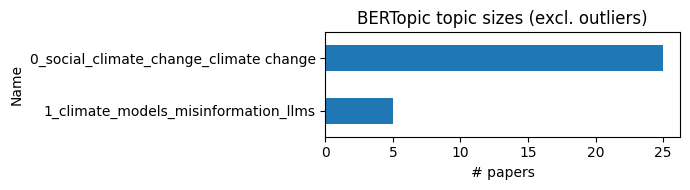

In [7]:
# Interactive barchart if plotly renders in this environment; otherwise a static fallback.
import matplotlib.pyplot as plt

try:
    fig = topic_model.visualize_barchart(top_n_topics=10, n_words=8)
    fig.show()
except Exception as e:
    print(f"Interactive barchart unavailable ({type(e).__name__}); showing static sizes.")

info = topic_model.get_topic_info()
info_plot = info[info["Topic"] != -1]
if len(info_plot):
    ax = info_plot.set_index("Name")["Count"].plot.barh(figsize=(7, 0.5 * len(info_plot) + 1))
    ax.set_xlabel("# papers")
    ax.set_title("BERTopic topic sizes (excl. outliers)")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()

## 3. LDA (gensim)

Bag-of-words preprocessing: lowercase, tokenize (alphabetic only), drop NLTK English
stopwords plus a small domain stoplist (`climate`, `change`, `social`, `media`, …),
lemmatize, and keep tokens longer than 2 characters. We then pick the number of topics with
a `c_v` coherence sweep and train the final model at a small fixed `k`.

In [39]:
import re
import nltk

for res in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(res, quiet=True)

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

DOMAIN_STOP = {
    "climate", "change", "paper", "study", "studies", "using", "use", "used",
    "data", "social", "media", "research", "result", "results", "approach",
    "model", "models", "analysis", "based", "also", "however", "propose", "proposed", 
    "science", "journal", "http", "doi", "environmental"
}
STOP = set(stopwords.words("english")) | DOMAIN_STOP
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    tokens = re.findall(r"[a-z]+", str(text).lower())
    return [lemmatizer.lemmatize(t) for t in tokens if len(t) > 2 and t not in STOP]

tokenized = [preprocess(t) for t in corpus["text"]]
print(f"Avg tokens/doc after cleaning: {np.mean([len(d) for d in tokenized]):.0f}")

Avg tokens/doc after cleaning: 142


In [40]:
from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel

dictionary = Dictionary(tokenized)
dictionary.filter_extremes(no_below=2, no_above=0.5)
bow_corpus = [dictionary.doc2bow(doc) for doc in tokenized]
print(f"Vocabulary after filtering: {len(dictionary)} terms")

# Coherence sweep over a small range of k (exploratory sanity check).
coherence = {}
for k in range(3, 6):
    m = LdaModel(bow_corpus, num_topics=k, id2word=dictionary,
                 passes=20, random_state=RANDOM_STATE)
    cm = CoherenceModel(model=m, texts=tokenized, dictionary=dictionary, coherence="c_v")
    coherence[k] = cm.get_coherence()

for k, c in coherence.items():
    print(f"k={k}: c_v coherence = {c:.3f}")

Vocabulary after filtering: 581 terms
k=3: c_v coherence = 0.288
k=4: c_v coherence = 0.377
k=5: c_v coherence = 0.293


In [41]:
# Pick the number of topics with the best c_v coherence from the sweep above.
# (On 30 docs the differences are small/unstable — override manually if a given k reads better.)
NUM_TOPICS = max(coherence, key=coherence.get)
print(f"Using NUM_TOPICS = {NUM_TOPICS} (best c_v = {coherence[NUM_TOPICS]:.3f})\n")

lda = LdaModel(bow_corpus, num_topics=NUM_TOPICS, id2word=dictionary,
               passes=20, random_state=RANDOM_STATE)

for i, topic in lda.print_topics(num_words=8):
    print(f"Topic {i}: {topic}\n")

Using NUM_TOPICS = 4 (best c_v = 0.377)

Topic 0: 0.020*"stance" + 0.017*"llm" + 0.016*"task" + 0.015*"misinformation" + 0.013*"large" + 0.010*"text" + 0.010*"accuracy" + 0.010*"sentiment"

Topic 1: 0.019*"polarization" + 0.017*"political" + 0.012*"online" + 0.012*"http" + 0.011*"topic" + 0.011*"policy" + 0.011*"affective" + 0.011*"discourse"

Topic 2: 0.035*"content" + 0.027*"credibility" + 0.027*"low" + 0.019*"tweet" + 0.019*"misinformation" + 0.014*"user" + 0.014*"high" + 0.011*"facebook"

Topic 3: 0.038*"network" + 0.021*"opinion" + 0.016*"debate" + 0.013*"user" + 0.012*"method" + 0.011*"topic" + 0.011*"discussion" + 0.009*"within"



In [42]:
def dominant_topic(bow):
    dist = lda.get_document_topics(bow)
    return max(dist, key=lambda x: x[1])[0] if dist else -1

corpus["lda_topic"] = [dominant_topic(b) for b in bow_corpus]
corpus[["paper_id", "title", "lda_topic"]].head(10)

,paper_id,title,lda_topic
0,06e5f45d08bfd760,Social media discourse as a window into energy...,1
1,1aecf98d861b4aea,Navigating the Map of Environmental-policy Nar...,3
2,295dd9e3895f13f1,Opinion-based homogeneity on youtube: Combinin...,1
3,2d9dff826cc1e5bd,Climate Change Myths Detection Using Dynamical...,0
4,3b8b0f6e81d0f3f5,ClimateCheck2025: Multi-Stage Retrieval Meets ...,0
5,4778b166d9eb776c,LLM-Supported Content Analysis of Motivated Re...,1
6,4b2e90eb151bcba8,Good and Bad Science? Spanish-Speaking YouTube...,1
7,5961178f6abd8ab1,Evolution of the Social Debate on Climate Cris...,3
8,62ec8e4d919c3894,AI could create a perfect storm of climate mis...,2
9,6a1bf5b3da32183d,Longitudinal Trends in Global Climate Change D...,0


### Interactive document map

Each paper is one point, positioned by a 2D projection of its **LDA topic-distribution
vector** and colored by its **dominant topic**. Hover to read the paper title (plus the
model's confidence and year). Papers that sit close together share a similar topic mixture.
We show two layouts of the same data — **UMAP** and **t-SNE** — since neither is canonical on
so few points.

> This is a *document-level* view. The classic *topic-level* interactive LDA plot is
> [`pyLDAvis`](https://github.com/bmabey/pyLDAvis) (intertopic-distance map + per-topic term
> bars) — it shows topics rather than titles, so it complements this view. Say the word and
> I'll add a `pyLDAvis` cell too.

In [43]:
import textwrap
import plotly.express as px
from sklearn.manifold import TSNE

# Full doc-topic probability matrix (rows = papers, cols = topics).
doc_topic = np.zeros((len(bow_corpus), NUM_TOPICS))
for i, bow in enumerate(bow_corpus):
    for t, p in lda.get_document_topics(bow, minimum_probability=0):
        doc_topic[i, t] = p

# Human-readable label per topic from its top words (shared legend).
topic_words = {t: ", ".join(w for w, _ in lda.show_topic(t, topn=4)) for t in range(NUM_TOPICS)}
hover_titles = ["<br>".join(textwrap.wrap(str(t), 55)) for t in corpus["title"]]

def document_map(coords, method):
    df = pd.DataFrame({
        "x": coords[:, 0],
        "y": coords[:, 1],
        "Dominant topic": [f"T{t}: {topic_words[t]}" for t in corpus["lda_topic"]],
        "title": hover_titles,
        "confidence": doc_topic.max(axis=1).round(2),
        "year": corpus["year"].values,
    })
    fig = px.scatter(
        df, x="x", y="y", color="Dominant topic",
        hover_name="title",
        hover_data={"confidence": True, "year": True,
                    "x": False, "y": False, "Dominant topic": False},
        title=f"LDA documents — 2D {method} of topic distributions (hover for title)",
    )
    fig.update_traces(marker=dict(size=13, line=dict(width=1, color="white")))
    fig.update_layout(width=850, height=600, legend_title_text="Dominant LDA topic",
                      xaxis_title=None, yaxis_title=None)
    return fig

# UMAP layout (n_neighbors small for the tiny corpus).
umap_coords = UMAP(n_neighbors=5, min_dist=0.2, metric="cosine",
                   random_state=RANDOM_STATE).fit_transform(doc_topic)
document_map(umap_coords, "UMAP").show()

# t-SNE layout (perplexity must be < n_samples; small for 30 docs).
tsne_coords = TSNE(n_components=2, perplexity=5, metric="cosine",
                   init="random", random_state=RANDOM_STATE).fit_transform(doc_topic)
document_map(tsne_coords, "t-SNE").show()

## 4. BERTopic vs LDA

Side-by-side topic assignment per paper, plus a cross-tabulation. Given the research-area
labels already seen in notebook 03 (mostly **Misinformation** vs **Polarization**), we
expect both methods to surface a similar high-level split — keeping in mind the small-corpus
caveat.

In [44]:
comparison = corpus[["paper_id", "title", "bertopic_topic", "lda_topic"]].copy()
comparison

,paper_id,title,bertopic_topic,lda_topic
0,06e5f45d08bfd760,Social media discourse as a window into energy...,0,1
1,1aecf98d861b4aea,Navigating the Map of Environmental-policy Nar...,0,3
2,295dd9e3895f13f1,Opinion-based homogeneity on youtube: Combinin...,0,1
3,2d9dff826cc1e5bd,Climate Change Myths Detection Using Dynamical...,0,0
4,3b8b0f6e81d0f3f5,ClimateCheck2025: Multi-Stage Retrieval Meets ...,1,0
5,4778b166d9eb776c,LLM-Supported Content Analysis of Motivated Re...,0,1
6,4b2e90eb151bcba8,Good and Bad Science? Spanish-Speaking YouTube...,0,1
7,5961178f6abd8ab1,Evolution of the Social Debate on Climate Cris...,0,3
8,62ec8e4d919c3894,AI could create a perfect storm of climate mis...,0,2
9,6a1bf5b3da32183d,Longitudinal Trends in Global Climate Change D...,0,0


In [45]:
# How BERTopic clusters map onto LDA dominant topics.
pd.crosstab(corpus["bertopic_topic"], corpus["lda_topic"],
            rownames=["BERTopic"], colnames=["LDA"])

LDA,0,1,2,3
BERTopic,,,,
0,5,13,3,4
1,4,0,0,1
